# **1. Load**
pandas reads the CSV into a DataFrame. Shape tells us how many rows and columns we have



In [34]:
import json
import pandas as pd
from pathlib import Path
import joblib
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, recall_score, precision_score, f1_score, accuracy_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
raw = pd.read_csv('telco_churn.csv')
print('Rows and columns:', raw.shape)
display(raw.head())

Rows and columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# **2. Check types**
A model cannot learn safely from strings pretending to be numbers.

In [35]:
print(raw.dtypes)
print('Missing values according to pandas:')
print(raw.isna().sum())
print('Full duplicate rows:', raw.duplicated().sum())
print('DUplicate customer IDs:', raw.customerID.duplicated().sum())
print('Blank TotalCharges strings:', raw.TotalCharges.astype(str).str.strip().eq('').sum())
print('Churn counts:')
print(raw.Churn.value_counts())
print('Churn rate:', f"{raw.Churn.eq('Yes').mean():.2%}")

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object
Missing values according to pandas:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessB

# **3. Clean**
TotalCharges is a text column because 11 entries are black strings. All 11 belong to customers whose tenure is 0 months, so we fill these specific missing totals with 0.0. Then drop customerID: arbitrary ID strings should not be predictors.

In [36]:
df = raw.drop_duplicates().copy()
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
missing_before = int(df['TotalCharges'].isna().sum())
zero_tenure_missing = df['TotalCharges'].isna() & df['tenure'].eq(0)
df.loc[zero_tenure_missing, 'TotalCharges'] = 0.0
assert df['TotalCharges'].notna().all(), 'Investigate unexpected missing charge values'
df = df.drop(columns=['customerID'])
print('Missing totals before cleaning:', missing_before)
print('Data shape after cleaning:', df.shape)
print('Remaining missing values:', df.isna().sum().sum())

Missing totals before cleaning: 11
Data shape after cleaning: (7043, 20)
Remaining missing values: 0


# **4. Exploratory Data Analysis**
We compare the fraction who churned inside each group, not just raw counts. The brief asks for contract, tenure, monthly charges and payment method


Churn rate by contract
Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churning, dtype: float64


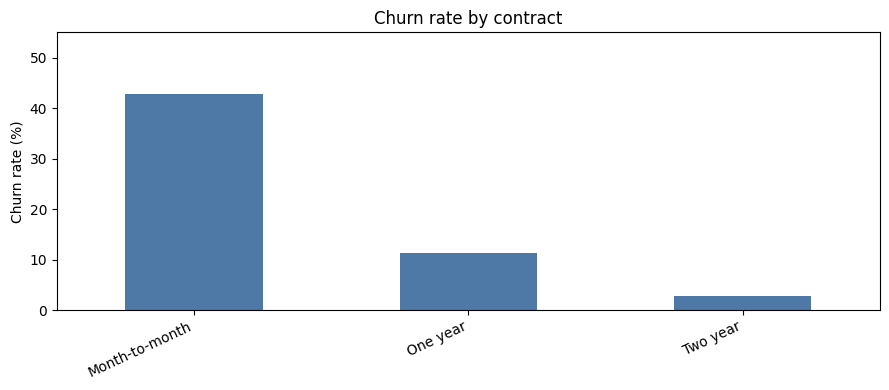


Churn rate by payment method
PaymentMethod
Electronic check             45.3
Mailed check                 19.1
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Name: Churning, dtype: float64


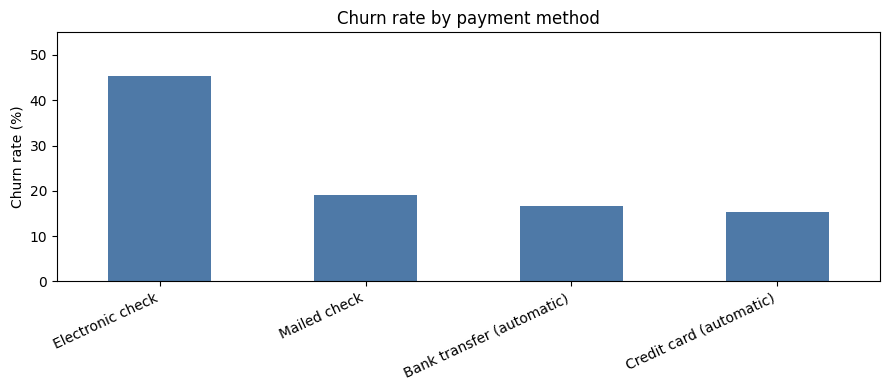

In [37]:
df['Churning'] = df['Churn'].eq('Yes').astype(int)

def plot_churn_rate(column, title):
   pct = (df.groupby(column, observed=True)['Churning'].mean() * 100).sort_values(ascending=False)
   print(f'\n{title}\n{pct.round(1)}')
   ax = pct.plot(kind='bar', figsize=(9, 4), color='#4e79A7')
   ax.set_title(title)
   ax.set_xlabel('')
   ax.set_ylabel('Churn rate (%)')
   ax.set_ylim(0, 55)
   plt.xticks(rotation=25, ha='right')
   plt.tight_layout()
   plt.show()

plot_churn_rate('Contract', 'Churn rate by contract')
plot_churn_rate('PaymentMethod', 'Churn rate by payment method')


Churn rate by tenure
TenureBand
0-12 months    47.4
13-24          28.7
25-48          20.4
49-72           9.5
Name: Churning, dtype: float64


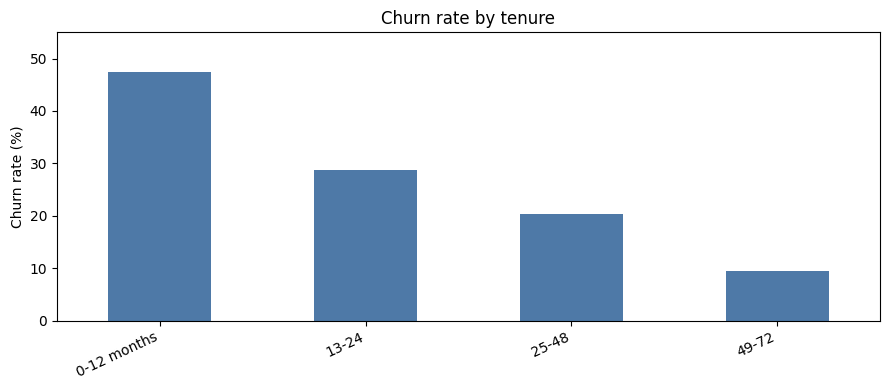


Churn rate by monthly bill quartile
MonthlyChargeBand
(70.35, 89.85]     37.5
(89.85, 118.75]    32.9
(35.5, 70.35]      24.6
(18.249, 35.5]     11.2
Name: Churning, dtype: float64


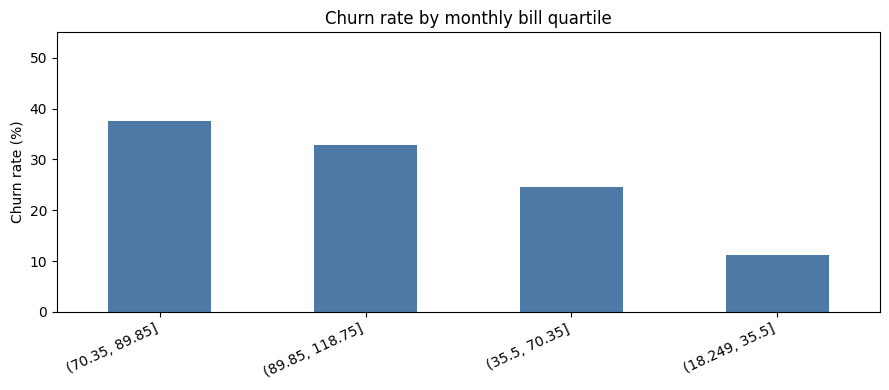

In [38]:
df['TenureBand'] = pd.cut(df['tenure'], bins=[-1, 12, 24, 48, 72], labels=['0-12 months', '13-24', '25-48', '49-72'])
df['MonthlyChargeBand'] = pd.qcut(df['MonthlyCharges'], q=4, duplicates='drop')
plot_churn_rate('TenureBand', 'Churn rate by tenure')
plot_churn_rate('MonthlyChargeBand', 'Churn rate by monthly bill quartile')

#### **EDA insights**
- Month-to-month contracts have 42.7% churn, versus among two year contracts
- Electronic check users have 45.3% churn versus 15.2% for automatic credit card payment.
- Customers with 0-12 months tenure have 47.4% churn, versus 9.5% at 49-72 months.
- Higher monthly-chrage groups also have higher observed chrun than the lowest-charge group, but the relationship is not monotonic.

These facts motivate possible retention actions but do not establish why churn happens.

# **5. Prepare the target and an 80/20 stratified split**
Churn is the target. Everything else is a feature.

**stratify=y** keeps the apporximate churn rate in both train and test sets. The test set stays untouched until final evaluation.

In [39]:
X = df.drop(columns=['Churn', 'Churning', 'TenureBand', 'MonthlyChargeBand'])
y = df['Churn'].map({'No': 0, 'Yes': 1})
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print('Train:', X_train.shape, '| churn:', round(y_train.mean(), 3))
print('Test:', X_test.shape, '| churn:', round(y_test.mean(), 3))

Train: (5634, 19) | churn: 0.265
Test: (1409, 19) | churn: 0.265


# **6. Pipeline**
Machine-learning models need consistent numerical inputs. StandardScaler centers/scales the numerical features; OneHotEncoder turns text categories (contract, internet type etc) into indicators columns. The pipeline fits preprocessing using the training fold only, preventing leakage into cross-validation and the test set.

In [40]:
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()
preprocessor = ColumnTransformer([
    ('numeric', Pipeline([('impute', SimpleImputer(strategy='median')),
                          ('scale', StandardScaler())]), num_cols),
    ('categorical', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                              ('onehot', OneHotEncoder(handle_unknown='ignore'))]), cat_cols)
])

print('Numeric:', num_cols)
print('Categorical:', cat_cols)

Numeric: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


# **7-8 Compare Logistic Regression, Decision Tree and Random Forest**
All classifiers use class_weight='balanced', to pay more attention to the minority churn class.

Recall = TP / (TP + FN). Missing a real churner is a false negative. High recall means fewer churners slip past the retention team. However, chasing recall without checking precision can produce too many false alarms.

5 startified folds within the training set only

,recall,precision,f1
Logistic Regression,0.8013,0.5169,0.6283
Decision Tree,0.7906,0.5003,0.6125
Random Forest,0.6408,0.5964,0.6176


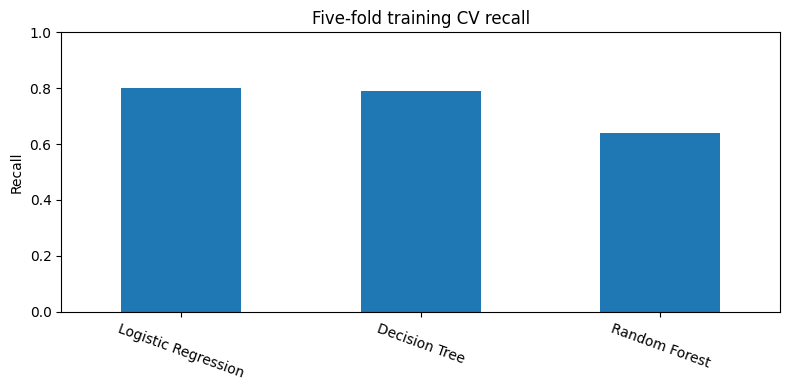

In [41]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced',
random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(max_depth=6, class_weight='balanced',
random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=150, min_samples_leaf=2, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
comparison = {}
for name, estimator in models.items():
  pipeline = Pipeline([('preprocessing', preprocessor), ('model', estimator)])
  scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=['recall', 'precision', 'f1'], n_jobs=-1)
  comparison[name] = {metric: round(float(scores[f'test_{metric}'].mean()), 4)
                      for metric in ['recall', 'precision', 'f1']}
results = pd.DataFrame(comparison).T.sort_values('recall', ascending=False)
display(results)
results['recall'].plot(kind='bar', title='Five-fold training CV recall', rot=-20, figsize=(8, 4), ylim=(0, 1))
plt.ylabel('Recall')
plt.tight_layout()
plt.show()

# **9. Tuning the strongest model**
We select the model based on training CV recall, breaking ties with F1. Then GridSearchCV searches a small set of hyperparameters, again only on the training folds. It never uses the held out test set for selecting the hyperparameters

In [45]:
best_name = max(comparison, key=lambda name: (comparison[name]['recall'], comparison[name]['f1']))
param_grids = {
    'Logistic Regression': {'model__C': [0.05, 0.1, 0.5, 1.0, 2.0, 5.0]},
    'Decision Tree': {'model__max_depth': [4, 6, 8], 'model__min_samples_leaf': [10, 25, 40]},
    'Random Forest': {'model__max_depth': [8, 12, None], 'model__min_samples': [2, 4]},
}
search = GridSearchCV(
    Pipeline([('preprocessing', preprocessor), ('model', models[best_name])]),
    param_grids[best_name], cv=cv, scoring='recall', n_jobs=-1, refit=True
)
search.fit(X_train, y_train)
final_model = search.best_estimator_
print('Model:', best_name)
print('Best parameters:', search.best_params_)
print('Tuned training CV recall:', round(search.best_score_, 4))

Model: Logistic Regression
Best parameters: {'model__C': 0.5}
Tuned training CV recall: 0.8013


# **10. Evaluate**
The confusion matrix counts correct and incorrect predictions. For churn as the positive class, the upper-right entry is false positive and the bottom-left is false negative. The classification report also displays precision, recall and F1.

              precision    recall  f1-score   support

      Stayed       0.90      0.72      0.80      1035
     Churned       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

Churn recall: 0.7834
Churn precision: 0.5034


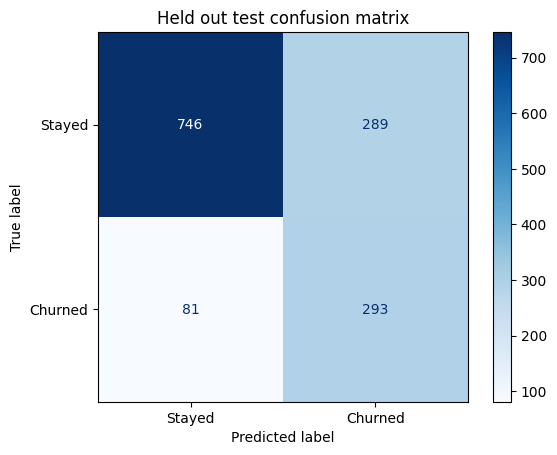

In [43]:
predictions = final_model.predict(X_test)
cm = confusion_matrix(y_test, predictions)
print(classification_report(y_test, predictions, target_names=['Stayed', 'Churned']))
print('Churn recall:', round(recall_score(y_test, predictions), 4))
print('Churn precision:', round(precision_score(y_test, predictions), 4))
ConfusionMatrixDisplay(cm, display_labels=['Stayed', 'Churned']).plot(cmap='Blues')
plt.title('Held out test confusion matrix')
plt.show()

# **11. Business recommendations**
1. **Offer optional plan changes to month-to-month customers** Compare retention offers using a small randomized experiment before rolling out widely.
2. **Create a first-year retention program** Onboarding and proactive check-ins may be relevant because churn is most common among short-tenure customers
3. **Test smoother payment experiences** Offer customers using electronic checks an optional auotpay setup and measure retention and customer satisfaction.
4. **Investigate high monthly bills and service support.** Survey dissatisfied customers and offer appropiate plans or support, without assuming the bill itself causes churn.

Business KPI: Track saved customers per intervention dollar, not just model recall. At a recall of roughly 78% the model catches many churners, but its false positives make blanket discounts expensive

In [44]:
joblib.dump(final_model, 'model.joblib')
holdout = {
    'recall': round(float(recall_score(y_test, predictions)), 4),
    'precision': round(float(precision_score(y_test, predictions)), 4),
    'f1': round(float(f1_score(y_test, predictions)), 4),
    'accuracy': round(float(accuracy_score(y_test, predictions)), 4)
}
metrics = {
    'cleaning': {'original_rows': len(raw), 'duplicate_rows': int(raw.duplicated().sum()),
                 'duplicate_customer_ids': int(raw.customerID.duplicated().sum()),
                 'missing_total_charges': int(zero_tenure_missing.sum())},
    'rows_after_cleaning': len(df), 'train_rows': len(X_train), 'test_rows': len(X_test),
    'historical_churn_rate': round(float(y.mean()), 4),
    'cv_comparison': comparison, 'selected_model': best_name,
    'tuned_parameters': search.best_params_, 'grid_cv_recall': round(float(search.best_score_), 4),
    'test_metrics': holdout, 'confusion_matrix': cm.tolist(),
    'classification_report': classification_report(y_test, predictions, target_names=['Stayed', 'Churned'], output_dict=True),
}

Path('metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
print('Saved model.joblib and metrics.json')
print('Test results:', holdout)

Saved model.joblib and metrics.json
Test results: {'recall': 0.7834, 'precision': 0.5034, 'f1': 0.613, 'accuracy': 0.7374}


# 13. Limitations
- Data is a snapshot, not a time-to-event dataset. The model classifies customers with characteristics associated with Churn=Yes, not a precise date of future departure.
- Group differences shwo correlation, not verified causal effects. A randomized retention trial can determine which actions actually save customers
- class_weight='balanced' improves attention to churners, but the output score are not probability-calibrate. Risk bands in the app are descriptive examples, not calibrated likelihoods.
- False positives matter: the thousands of customers, automatic discounts to everyone flagged can be expensive. Evaluate intervention costs, calibration and performance on fresh data before real deployment